# Projeto SETA - Classificador supervisionado


### 1) Qual a base escolhida?

https://archive.ics.uci.edu/ml/datasets/Covertype

In [13]:
%pip install ucimlrepo
%pip install matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
from ucimlrepo import fetch_ucirepo 
  
# Traz os dados da base Covertype (ID 31)
covertype = fetch_ucirepo(id=31) 
  
# Separa as features (X) e a classe (y) em formato Pandas DataFrame
X = covertype.data.features 
y = covertype.data.targets 

print(X.head())

   Elevation  Aspect  Slope  Horizontal_Distance_To_Hydrology  \
0       2596      51      3                               258   
1       2590      56      2                               212   
2       2804     139      9                               268   
3       2785     155     18                               242   
4       2595      45      2                               153   

   Vertical_Distance_To_Hydrology  Horizontal_Distance_To_Roadways  \
0                               0                              510   
1                              -6                              390   
2                              65                             3180   
3                             118                             3090   
4                              -1                              391   

   Hillshade_9am  Hillshade_Noon  Hillshade_3pm  \
0            221             232            148   
1            220             235            151   
2            234             238   

### 2) **(10%)** Pré-processamento: entendimento do conjunto de dados
- Quais são minhas features?

- Quais são minhas classes?
- Como estão distribuidas minhas classes?
- Checagem se os valores estão dentro de um limite permitido ou razoável.
- Tratamento de valores ausentes por eliminação ou substituição.
- Conversão do tipo de dados.


In [15]:
# Mostra o tamanho do dataset e os nomes das colunas
print(f"Quantidade de observações (linhas): {X.shape[0]}")
print(f"Quantidade de features (colunas): {X.shape[1]}")

# Lista os nomes de todas as 54 colunas de features
print("Nomes de todas as features:")
print(list(X.columns))

Quantidade de observações (linhas): 581012
Quantidade de features (colunas): 54
Nomes de todas as features:
['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area1', 'Soil_Type1', 'Soil_Type2', 'Soil_Type3', 'Soil_Type4', 'Soil_Type5', 'Soil_Type6', 'Soil_Type7', 'Soil_Type8', 'Soil_Type9', 'Soil_Type10', 'Soil_Type11', 'Soil_Type12', 'Soil_Type13', 'Soil_Type14', 'Soil_Type15', 'Soil_Type16', 'Soil_Type17', 'Soil_Type18', 'Soil_Type19', 'Soil_Type20', 'Soil_Type21', 'Soil_Type22', 'Soil_Type23', 'Soil_Type24', 'Soil_Type25', 'Soil_Type26', 'Soil_Type27', 'Soil_Type28', 'Soil_Type29', 'Soil_Type30', 'Soil_Type31', 'Soil_Type32', 'Soil_Type33', 'Soil_Type34', 'Soil_Type35', 'Soil_Type36', 'Soil_Type37', 'Soil_Type38', 'Soil_Type39', 'Soil_Type40', 'Wilderness_Area2', 'Wilderness_Area3', 'Wilderness_A

C:\Users\gcdgg\AppData\Local\Temp\ipykernel_30156\2588994518.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=y, x=target_col, palette="viridis")


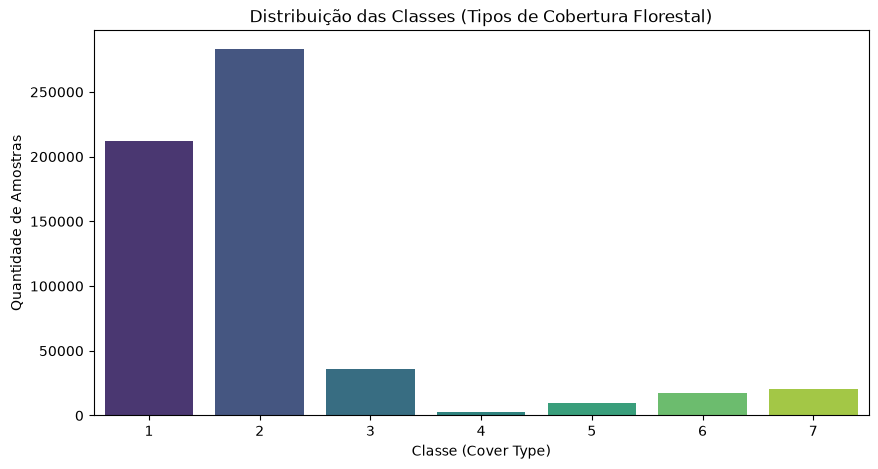


Porcentagem de cada classe na base:
Cover_Type
2             48.759922
1             36.460521
3              6.153746
7              3.530048
6              2.989095
5              1.633873
4              0.472796
Name: proportion, dtype: float64


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define a coluna alvo diretamente nesta célula
target_col = y.columns[0]

# Configura o tamanho do gráfico
plt.figure(figsize=(10, 5))

# Cria o gráfico de contagem
sns.countplot(data=y, x=target_col, palette="viridis")
plt.title("Distribuição das Classes (Tipos de Cobertura Florestal)")
plt.ylabel("Quantidade de Amostras")
plt.xlabel("Classe (Cover Type)")
plt.show()

# Exibe a porcentagem exata de cada classe
print("\nPorcentagem de cada classe na base:")
print(y.value_counts(normalize=True) * 100)

In [5]:
display(X.describe())

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4
count,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,...,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000
mean,2959.365301,155.656807,14.103704,269.428217,46.418855,2350.146611,212.146049,223.318716,142.528263,1980.291226,...,0.002773,0.003255,0.000205,0.000513,0.026803,0.023762,0.015060,0.051434,0.436074,0.063627
std,279.984734,111.913721,7.488242,212.549356,58.295232,1559.254870,26.769889,19.768697,38.274529,1324.195210,...,0.052584,0.056957,0.014310,0.022641,0.161508,0.152307,0.121791,0.220882,0.495897,0.244087
min,1859.000000,0.000000,0.000000,0.000000,-173.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2809.000000,58.000000,9.000000,108.000000,7.000000,1106.000000,198.000000,213.000000,119.000000,1024.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2996.000000,127.000000,13.000000,218.000000,30.000000,1997.000000,218.000000,226.000000,143.000000,1710.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,3163.000000,260.000000,18.000000,384.000000,69.000000,3328.000000,231.000000,237.000000,168.000000,2550.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,3858.000000,360.000000,66.000000,1397.000000,601.000000,7117.000000,254.000000,254.000000,254.000000,7173.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [6]:
print(f"Valores nulos em X: {X.isnull().sum().sum()}")
print(f"Valores nulos em y: {y.isnull().sum().sum()}")

Valores nulos em X: 0
Valores nulos em y: 0


In [7]:
print(X.dtypes.unique())

[dtype('int64')]


### 3) **(80%)** Nos blocos seguintes implemente seus classificadores (serão implementados 2 métodos diferentes).

#### 3.1) Qual método escolhido?

**Indique o método escolhido**

Vector Method

#### 3.2) **(10%)** Baseline - Implemente seu classificador da forma mais simples possível para esse ser seu baseline

In [11]:
from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split

# 1. Carrega a base de dados Covertype
covertype = fetch_covtype(as_frame=True)
X = covertype.data
y = covertype.target

# 2. Divide os dados em 70% Treino e 30% Teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Amostras de Treino: {X_train.shape[0]}")
print(f"Amostras de Teste:  {X_test.shape[0]}")

Amostras de Treino: 406708
Amostras de Teste:  174304


--- BASELINE ---
Acurácia no Treino: 0.6479
Acurácia no Teste:  0.6463

Relatório de Classificação (Teste):
              precision    recall  f1-score   support

           1       0.67      0.55      0.61     63552
           2       0.64      0.85      0.73     84991
           3       0.65      0.35      0.46     10726
           4       0.42      0.42      0.42       824
           5       0.00      0.00      0.00      2848
           6       0.37      0.18      0.24      5210
           7       0.61      0.04      0.08      6153

    accuracy                           0.65    174304
   macro avg       0.48      0.34      0.36    174304
weighted avg       0.63      0.65      0.62    174304



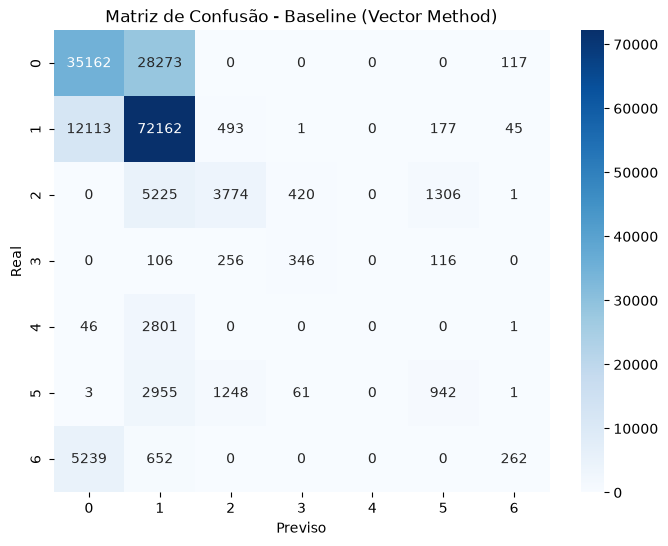

In [12]:
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 3.2 Baseline - Classificador baseado em Vetores simples
baseline_model = SGDClassifier(loss='hinge', random_state=42, max_iter=1000)
baseline_model.fit(X_train, y_train)

# Previsões
y_pred_train_base = baseline_model.predict(X_train)
y_pred_test_base = baseline_model.predict(X_test)

# Métricas
acc_train_base = accuracy_score(y_train, y_pred_train_base)
acc_test_base = accuracy_score(y_test, y_pred_test_base)

print(f"--- BASELINE ---")
print(f"Acurácia no Treino: {acc_train_base:.4f}")
print(f"Acurácia no Teste:  {acc_test_base:.4f}")
print("\nRelatório de Classificação (Teste):")
print(classification_report(y_test, y_pred_test_base, zero_division=0))

# Gráfico da Matriz de Confusão
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_test_base), annot=True, fmt='d', cmap='Blues')
plt.title("Matriz de Confusão - Baseline (Vector Method)")
plt.xlabel("Previso")
plt.ylabel("Real")
plt.show()

#### 3.3) **(20%)** Versão 1 - O que podemos fazer para melhorar nosso baseline? Aplique técnicas como redução de dimensionalidade, normalização ou outras. Compare os resultados.

#### 3.4) **(10%)** Tunning - Agora que temos um resultado promissor, vamos tentar melhorar o resultado alterando um ou mais hiper-parametro. Compare os resultados.

#### 3.5) Qual método escolhido?

**Indique o método escolhido**

#### 3.6) **(10%)** Baseline - Implemente seu classificador da forma mais simples possível para esse ser seu baseline

#### 3.7) **(20%)** Versão 1 - O que podemos fazer para melhorar nosso baseline? Aplique técnicas como redução de dimensionalidade, normalização ou outras. Compare os resultados.

#### 3.8) **(10%)** Tunning - Agora que temos um resultado promissor, vamos tentar melhorar o resultado alterando um ou mais hiper-parametro. Compare os resultados.

In [0]:
# Implementação. Use mais blocos se achar que ficará mais organizado.

### 5) **(10%)** Conclusões

*Compare seus resultados. Imaginando que sua solução fosse para produção, qual deles você escolheria? Por que? Quais os riscos você enxerga? O que recomendaria de próximos passos para melhorar os resultados?*